## Helper Functions

### Helper function to visualize the images with their respective RGB 3D distribution


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objs as go

def visualize_images_and_distributions(source, target, result, subsample_factor=10, interactive_plot=False):
    """
    Display source, target, and result images (top row)
    and their RGB color distributions (bottom row).

    Parameters
    ----------
    source, target, result : np.ndarray
        Input images in RGB format (values in [0, 1] or [0, 255]).
    subsample_factor : int, optional
        Factor by which to subsample pixels for faster visualization (default=10).
    interactive_plot : bool, optional
        If True, shows Plotly 3D interactive color distributions (separate windows).
        If False, shows them in static Matplotlib 3D plots.
    """

    def preprocess_image(img):
        """Ensure image is float in [0,1] and flattened."""
        if img.dtype == np.uint8:
            img = img / 255.0
        X = img.reshape((-1, 3))
        if subsample_factor > 1:
            nb = int(X.shape[0] / subsample_factor)
            r = np.random.RandomState(42)
            idx = r.randint(X.shape[0], size=(nb,))
            X = X[idx, :]
        return X

    # Prepare data
    imgs = {
        "Source": (source, preprocess_image(source)),
        "Target": (target, preprocess_image(target)),
        "Result": (result, preprocess_image(result))
    }

    # === Create a 2x3 Matplotlib figure ===
    fig = plt.figure(figsize=(15, 10), constrained_layout=True)

    # --- Top row: original images ---
    for i, (title, (img, _)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i)
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    # --- Bottom row: 3D RGB distributions ---
    for i, (title, (_, Xs)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i + 3, projection='3d')
        ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=Xs, s=8)
        ax.set_xlabel("R")
        ax.set_ylabel("G")
        ax.set_zlabel("B")
        ax.set_title(f"{title} RGB Distribution")
        ax.view_init(elev=20, azim=135)

    fig.suptitle("Image Comparison and 3D RGB Distributions", fontsize=15, y=0.98)
    plt.show()

    # === Optional interactive version ===
    if interactive_plot:
        for title, (_, Xs) in imgs.items():
            fig_plotly = go.Figure(data=[go.Scatter3d(
                x=Xs[:, 0],
                y=Xs[:, 1],
                z=Xs[:, 2],
                mode='markers',
                marker=dict(
                    size=2,
                    color=['rgb({},{},{})'.format(int(r*255), int(g*255), int(b*255))
                           for r, g, b in Xs]
                )
            )])
            fig_plotly.update_layout(
                scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B'),
                width=700,
                height=600,
                title=f"3D RGB Distribution ({title})"
            )
            fig_plotly.show()

## Per channel histogram matching method

### Import the libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import color

### Define the color transfer function

In [4]:
def histogram_match_per_channel(target, source, color_space='lab'):
    """
    Perform per-channel histogram matching between two images.
    Works in either RGB or Lab color space.
    Correctly handles different image sizes using quantile interpolation.
    """

    # === Convert color space ===
    if color_space.lower() == 'lab':
        # convert from uint8 to float [0,1]
        if source.dtype == np.uint8:
            source = source / 255.0
            target = target / 255.0
        source_cs = color.rgb2lab(source)
        target_cs = color.rgb2lab(target)
    elif color_space.lower() == 'rgb':
        source_cs = source.astype(np.float64).copy()
        target_cs = target.astype(np.float64).copy()
    else:
        raise ValueError("color_space must be 'rgb' or 'lab'")

    Hs, Ws, _ = source_cs.shape
    Ht, Wt, _ = target_cs.shape

    result_cs = np.zeros_like(source_cs)

    # === Histogram matching per channel with quantile interpolation ===
    for c in range(3):

        # Flatten channel
        u = source_cs[:, :, c].reshape(-1)   # size Ns
        v = target_cs[:, :, c].reshape(-1)   # size Nt

        Ns = u.size
        Nt = v.size

        # Sort both
        u_sorted, u_idx = np.sort(u), np.argsort(u)
        v_sorted = np.sort(v)

        # Quantile grids
        p_u = np.linspace(0.0, 1.0, Ns)
        p_v = np.linspace(0.0, 1.0, Nt)

        # Interpolate v at source quantiles
        v_interp = np.interp(p_u, p_v, v_sorted)

        # Reassign to match original ordering of u
        u_new = np.zeros_like(u)
        u_new[u_idx] = v_interp

        # Reshape back
        result_cs[:, :, c] = u_new.reshape(Hs, Ws)

    # === Convert back to RGB if needed ===
    if color_space.lower() == 'lab':
        result_rgb = color.lab2rgb(result_cs)
        result_rgb = np.clip(result_rgb, 0, 1)
        return (result_rgb * 255).astype(np.uint8)
    else:
        return np.clip(result_cs, 0, 255).astype(source.dtype)


### Test

In [5]:
source = plt.imread("ColabFiles/source.jpg")
target = plt.imread("ColabFiles/target.jpg")
res_rgb = histogram_match_per_channel(target, source, color_space='rgb')
res_lab = histogram_match_per_channel(target, source, color_space='lab')

### Compare the results on both RGB and Lab color spaces

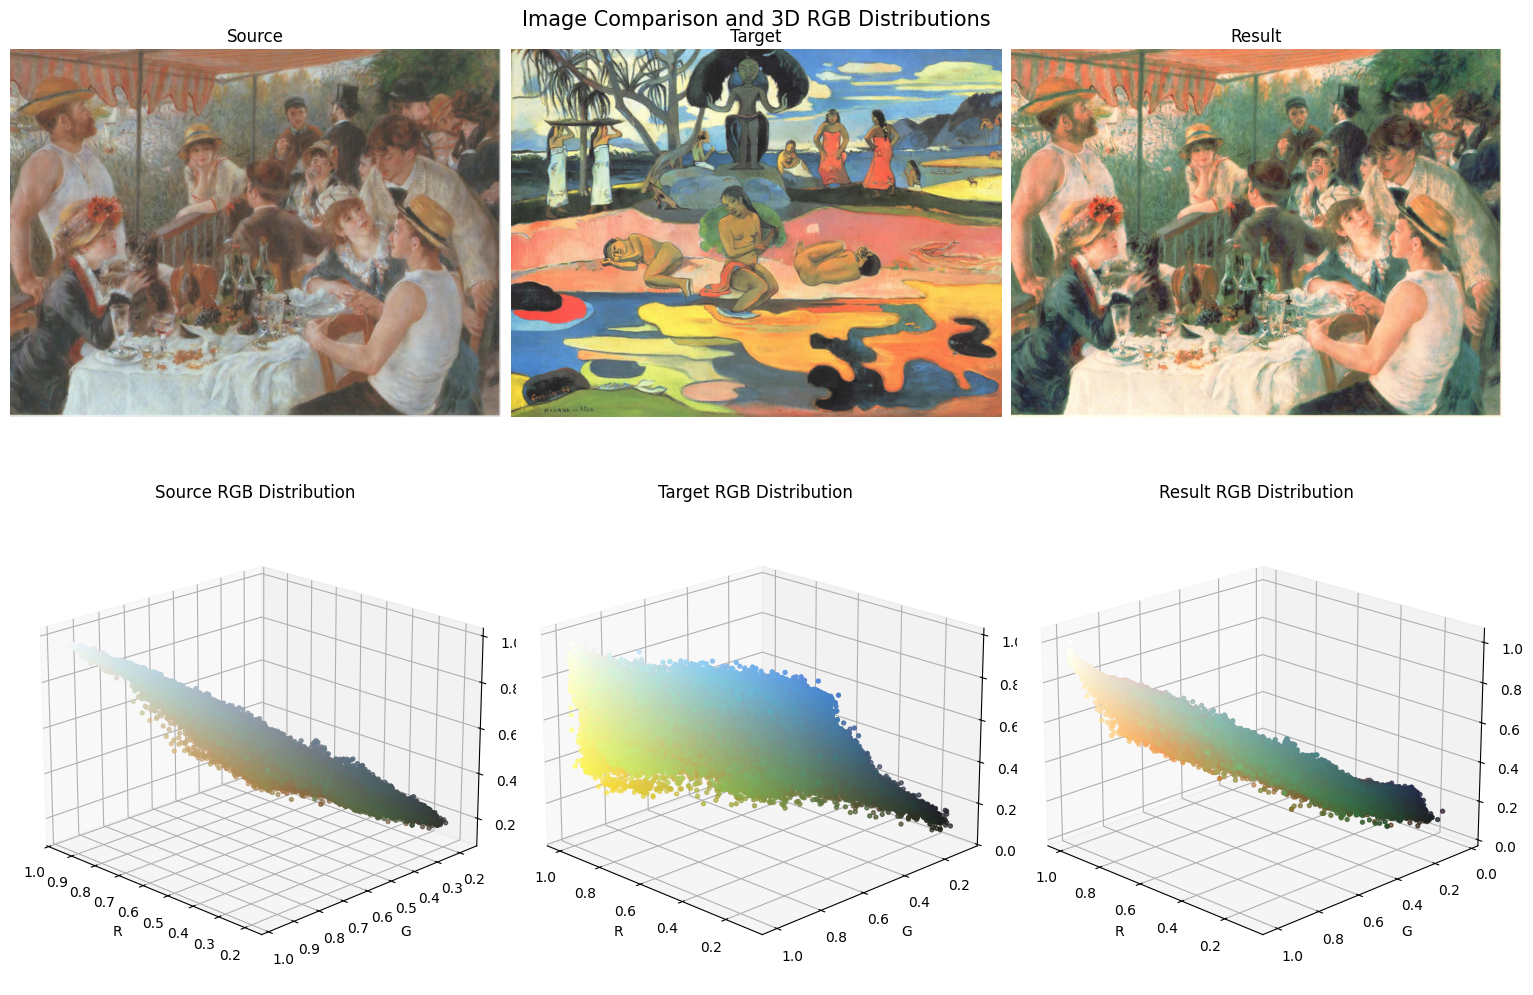

In [6]:
visualize_images_and_distributions(source, target, res_rgb, subsample_factor=10, interactive_plot=False)

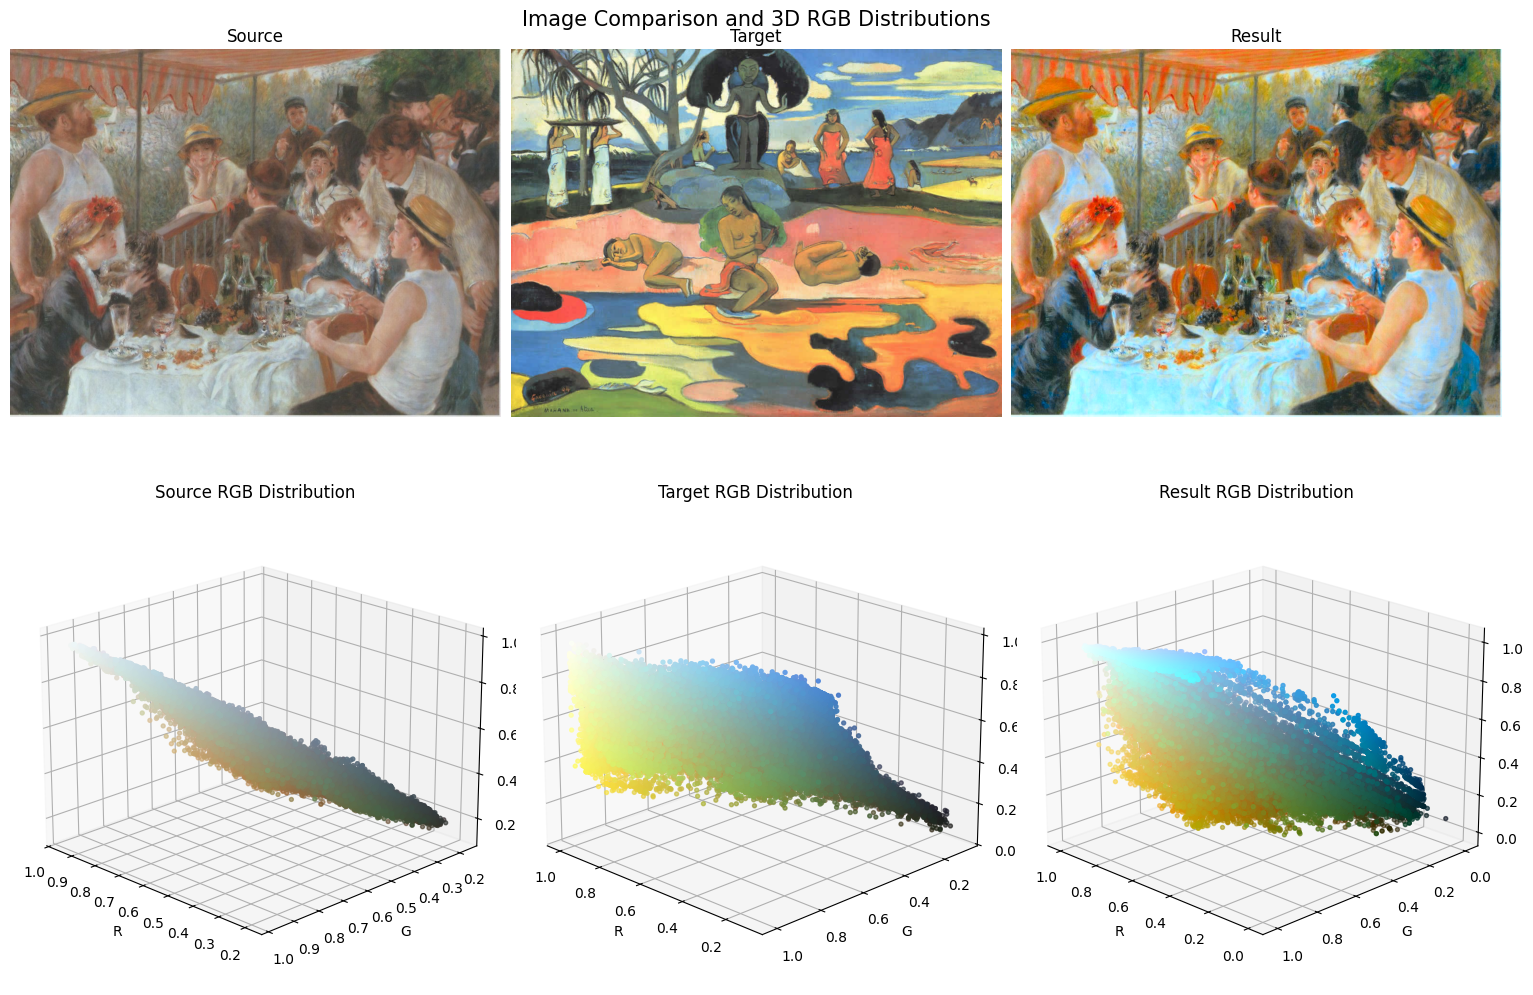

In [7]:
visualize_images_and_distributions(source, target, res_lab, subsample_factor=10, interactive_plot=False)